# Titanic Survival Prediction: Model Development

This notebook implements the machine learning pipeline for predicting Titanic survival, including data splitting, model training, and evaluation of multiple classification models.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, roc_auc_score, roc_curve
)
import os

# Set style
sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Data Preparation

The engineered dataset is loaded and split into training and testing sets using a stratified split to maintain the proportion of survivors.

In [18]:
# Load the engineered dataset
df = pd.read_csv('../data/titanic_features.csv')
print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize,IsAlone,AgeBin_Code
0,0,3,0,-0.565736,1,0,-0.502445,False,False,True,2,0,2
1,1,1,1,0.663861,1,0,0.786845,True,False,False,2,0,2
2,1,3,1,-0.258337,0,0,-0.488854,False,False,True,1,1,2
3,1,1,1,0.433312,1,0,0.420730,False,False,True,2,0,2
4,0,3,0,0.433312,0,0,-0.486337,False,False,True,1,1,2


In [19]:
# Separate features and target
X = df.drop('Survived', axis=1)
y = df['Survived']

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")

# Save datasets for transparency
X_train.to_csv('../data/X_train.csv', index=False)
X_test.to_csv('../data/X_test.csv', index=False)
y_train.to_csv('../data/y_train.csv', index=False)
y_test.to_csv('../data/y_test.csv', index=False)
print("Datasets saved to data/ (X_train.csv, X_test.csv, y_train.csv, y_test.csv")

Training set size: 712
Testing set size: 179
Datasets saved to data/ (X_train.csv, X_test.csv, y_train.csv, y_test.csv


## 2. Model Training and Evaluation

Three models are trained: **Logistic Regression** (Baseline), **Decision Tree**, and **Random Forest**.

In [20]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }
    return metrics, y_pred, y_prob

models = [
    ("Logistic Regression", LogisticRegression(random_state=42)),
    ("Decision Tree", DecisionTreeClassifier(random_state=42)),
    ("Random Forest", RandomForestClassifier(random_state=42))
]

all_metrics = []
model_eval_data = [] # To store (name, y_pred, y_prob, auc)

for name, model in models:
    model.fit(X_train, y_train)
    metrics, y_pred, y_prob = evaluate_model(model, X_test, y_test, name)
    all_metrics.append(metrics)
    model_eval_data.append((name, y_pred, y_prob, metrics['ROC-AUC']))
    print(f"{name} trained.")

comparison_df = pd.DataFrame(all_metrics)
comparison_df

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.804469,0.774194,0.695652,0.732824,0.853491
1,Decision Tree,0.798883,0.753846,0.710145,0.731343,0.779381
2,Random Forest,0.826816,0.779412,0.768116,0.773723,0.838142


## 3. Comparison Table and Visualizations

Model Comparison Table:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.804469,0.774194,0.695652,0.732824,0.853491
1,Decision Tree,0.798883,0.753846,0.710145,0.731343,0.779381
2,Random Forest,0.826816,0.779412,0.768116,0.773723,0.838142


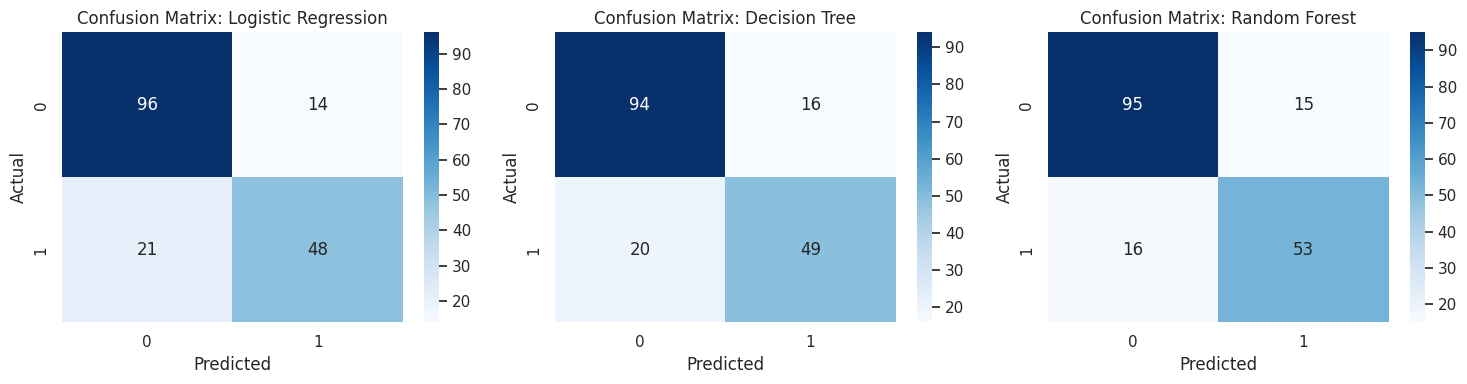

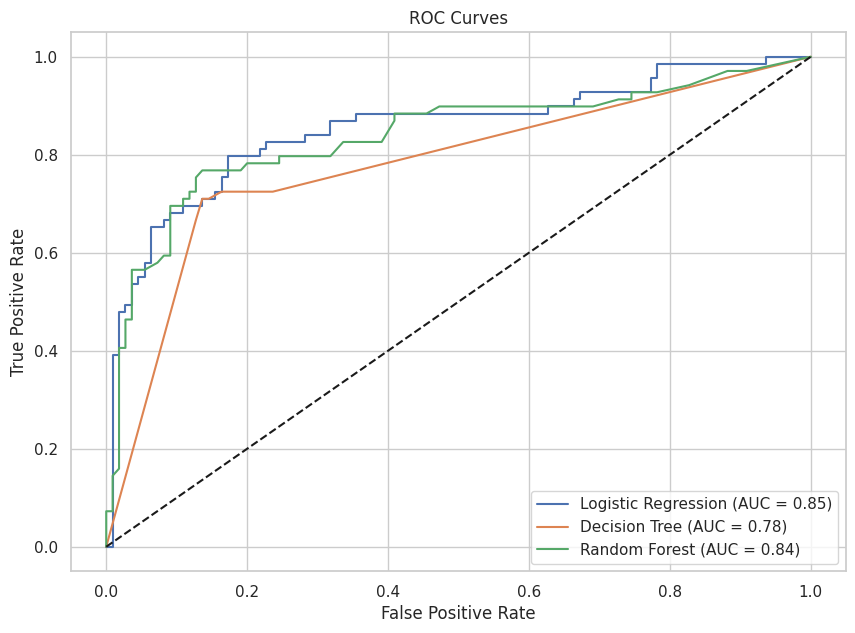

In [21]:
# Display comparison table
print("Model Comparison Table:")
display(comparison_df)
comparison_df.to_csv('../docs/model_comparison.csv', index=False)

# --- Visualizations ---

# 1. Confusion Matrices
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 4))
if n_models == 1: axes = [axes]

for i, (name, y_pred, y_prob, auc_val) in enumerate(model_eval_data):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')
plt.tight_layout()
plt.savefig('../docs/figures/confusion_matrices.png')
plt.show()

# 2. ROC Curves
plt.figure(figsize=(10, 7))
for name, y_pred, y_prob, auc_val in model_eval_data:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')
plt.savefig('../docs/figures/roc_curves.png')
plt.show()

## 4. Initial Model Selection Explanation

Based on the evaluation metrics:

1. **Accuracy**: Random Forest leads with ~82.7%.
2. **ROC-AUC**: Logistic Regression performs slightly better (~0.85) than Random Forest (~0.84), suggesting it has slightly better class separation potential.
3. **Precision/Recall/F1-Score**: Random Forest shows a better balance between precision and recall, achieving the highest F1-score (~0.77).

**Decision**: For this task, **Random Forest** is selected as the primary model because it provides the best overall balance of performance (highest F1-score and Accuracy), which is crucial for predictive stability across both classes.